In [ ]:
# 1. IMPORTAR LIBRERÍAS

import os
import zipfile
import shutil
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
# 2. SUBIR DATASET ZIP


from google.colab import files

uploaded = files.upload()

ZIP_PATH = list(uploaded.keys())[0]

print("Dataset cargado correctamente:")
print(ZIP_PATH)

Saving Dataset_Personas_Imagenes_224x224.zip to Dataset_Personas_Imagenes_224x224.zip
Dataset cargado correctamente:
Dataset_Personas_Imagenes_224x224.zip


In [ ]:
# ============================================
# 3. EXTRAER DATASET
# ============================================

EXTRACT_PATH = "/content/dataset_personas"

if os.path.exists(EXTRACT_PATH):
    shutil.rmtree(EXTRACT_PATH)

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extraído correctamente.")

Dataset extraído correctamente.


In [ ]:
# ============================================
# 4. BUSCAR CARPETA DEL DATASET
# ============================================

for root, dirs, files_list in os.walk(EXTRACT_PATH):
    if files_list:
        print(root)
        break

/content/dataset_personas/Dataset_Personas_Imagenes_224x224/Dataset_Personas_Imagenes_224x224/Dataset_Personas_Imagenes/Persona 25


In [ ]:
# ============================================
# 5. LOCALIZAR CARPETAS DE CLASES
# ============================================

DATASET_PATH = None

for root, dirs, files_list in os.walk(EXTRACT_PATH):

    carpetas_con_imagenes = 0

    for carpeta in dirs:
        ruta_carpeta = os.path.join(root, carpeta)

        archivos = os.listdir(ruta_carpeta)

        imagenes = [
            archivo for archivo in archivos
            if archivo.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            )
        ]

        if len(imagenes) > 0:
            carpetas_con_imagenes += 1

    if carpetas_con_imagenes >= 2:
        DATASET_PATH = root
        break

print("Ruta encontrada:")
print(DATASET_PATH)

Ruta encontrada:
/content/dataset_personas/Dataset_Personas_Imagenes_224x224/Dataset_Personas_Imagenes_224x224/Dataset_Personas_Imagenes


In [ ]:
# ============================================
# 6. OBTENER CLASES
# ============================================

class_names = sorted([
    carpeta
    for carpeta in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, carpeta))
])

print("Cantidad de clases:", len(class_names))

for i, clase in enumerate(class_names):
    print(i, "->", f"clase_{i+1:02d}")

Cantidad de clases: 30
0 -> clase_01
1 -> clase_02
2 -> clase_03
3 -> clase_04
4 -> clase_05
5 -> clase_06
6 -> clase_07
7 -> clase_08
8 -> clase_09
9 -> clase_10
10 -> clase_11
11 -> clase_12
12 -> clase_13
13 -> clase_14
14 -> clase_15
15 -> clase_16
16 -> clase_17
17 -> clase_18
18 -> clase_19
19 -> clase_20
20 -> clase_21
21 -> clase_22
22 -> clase_23
23 -> clase_24
24 -> clase_25
25 -> clase_26
26 -> clase_27
27 -> clase_28
28 -> clase_29
29 -> clase_30


In [ ]:
# ============================================
# 7. CONFIGURACIÓN
# ============================================

IMG_SIZE = (128, 128)
CHANNELS = 3

X = []
y = []

print("Tamaño de imagen:", IMG_SIZE)
print("Canales:", CHANNELS)

Tamaño de imagen: (128, 128)
Canales: 3


In [ ]:
# ============================================
# 8. CARGAR IMÁGENES
# ============================================

from tensorflow.keras.preprocessing.image import load_img, img_to_array

X = []
y = []

for class_index, class_name in enumerate(class_names):

    class_path = os.path.join(DATASET_PATH, class_name)

    for file_name in os.listdir(class_path):

        file_path = os.path.join(class_path, file_name)

        if not file_name.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        ):
            continue

        try:

            image = load_img(
                file_path,
                target_size=IMG_SIZE,
                color_mode="rgb"
            )

            image_array = img_to_array(image)

            # Normalización 0-1
            image_array = image_array / 255.0

            X.append(image_array)
            y.append(class_index)

        except Exception as error:

            print("Error:", file_path)
            print(error)

X = np.array(X, dtype=np.float32)
y = np.array(y)

print("X:", X.shape)
print("y:", y.shape)

X: (300, 128, 128, 3)
y: (300,)


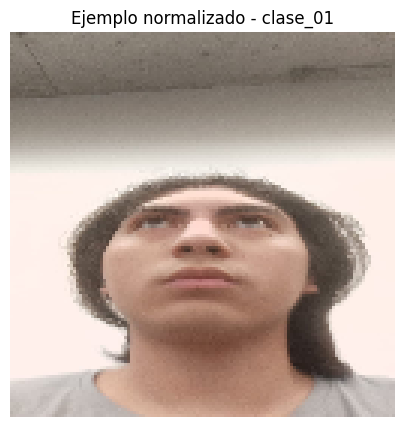

In [ ]:
# ============================================
# 9. VISUALIZAR IMAGEN
# ============================================

plt.figure(figsize=(5, 5))

plt.imshow(X[0])

plt.title(
    f"Ejemplo normalizado - clase_{y[0]+1:02d}"
)

plt.axis("off")
plt.show()

In [ ]:
# ============================================
# 10. TRAIN / TEST
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos entrenamiento:", X_train.shape)
print("Datos prueba:", X_test.shape)

Datos entrenamiento: (240, 128, 128, 3)
Datos prueba: (60, 128, 128, 3)


In [ ]:
# ============================================
# 11. CREAR MODELO CNN
# ============================================

NUM_CLASSES = len(class_names)

model = models.Sequential([

    layers.Input(
        shape=(128, 128, 3)
    ),

    # Primera convolución
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Segunda convolución
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Tercera convolución
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,308,510 (12.62 MB)

 Trainable params: 3,308,510 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================
# 12. COMPILAR MODELO
# ============================================

model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Modelo compilado correctamente.")

Modelo compilado correctamente.


In [ ]:
# ============================================
# 13. ENTRENAMIENTO
# ============================================

EPOCHS = 30
BATCH_SIZE = 16

history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_test,
        y_test
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    verbose=1
)

Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 704ms/step - accuracy: 0.0083 - loss: 3.5713 - val_accuracy: 0.0667 - val_loss: 3.3881
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 559ms/step - accuracy: 0.0583 - loss: 3.3421 - val_accuracy: 0.0833 - val_loss: 3.2504
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 682ms/step - accuracy: 0.2250 - loss: 2.8865 - val_accuracy: 0.2833 - val_loss: 2.6552
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 686ms/step - accuracy: 0.4500 - loss: 1.9601 - val_accuracy: 0.5000 - val_loss: 2.0853
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 576ms/step - accuracy: 0.7000 - loss: 1.0832 - val_accuracy: 0.5167 - val_loss: 2.0860
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 574ms/step - accuracy: 0.8250 - loss: 0.6206 - val_accuracy: 0.5500 - val_loss: 2.1285
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 684ms/step - accuracy: 0.9083 - loss: 0.3602 - val_accuracy: 0.5833 - val_loss: 1.9928
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 693ms/step - accuracy: 0.9417 - loss: 0.2165 - val_accur

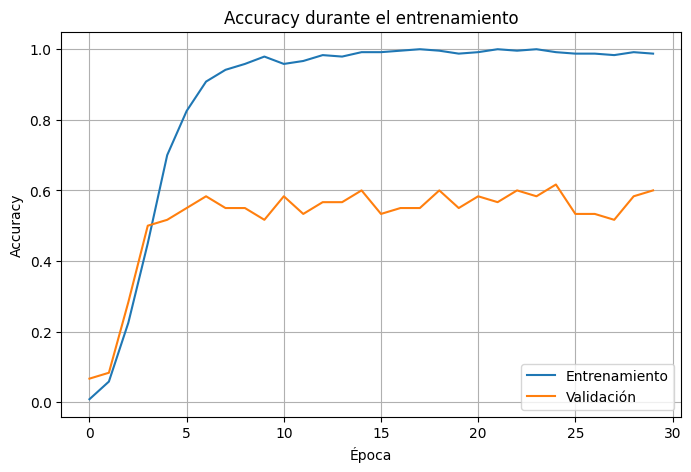

In [ ]:
# ============================================
# 14. GRÁFICO ACCURACY
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Entrenamiento"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validación"
)

plt.title("Accuracy durante el entrenamiento")

plt.xlabel("Época")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

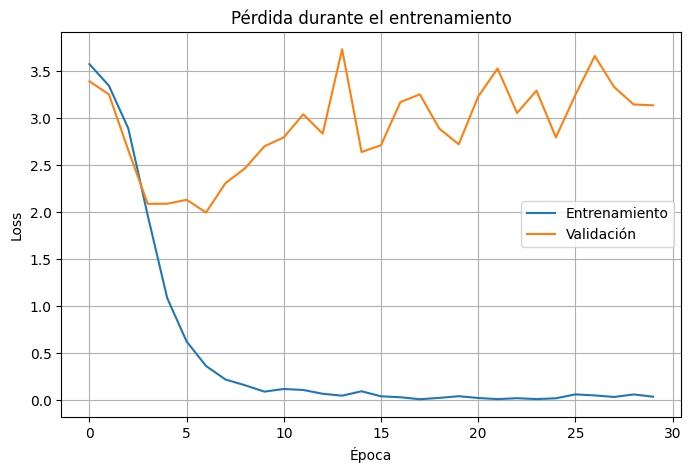

In [ ]:
# ============================================
# 15. GRÁFICO LOSS
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    history.history["val_loss"],
    label="Validación"
)

plt.title("Pérdida durante el entrenamiento")

plt.xlabel("Época")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [ ]:
# ============================================
# 16. PREDICCIONES
# ============================================

y_probability = model.predict(X_test)

y_pred = np.argmax(
    y_probability,
    axis=1
)

print("Predicciones realizadas correctamente.")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 337ms/step
Predicciones realizadas correctamente.


In [ ]:
# ============================================
# 17. MÉTRICAS
# ============================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("================================")
print("RESULTADOS CNN")
print("================================")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

RESULTADOS CNN
Accuracy : 0.6000
Precision: 0.5872
Recall   : 0.6000
F1-Score : 0.5806


In [ ]:
# ============================================
# 18. REPORTE DE CLASIFICACIÓN
# ============================================

nombres_clases = [
    f"clase_{i+1:02d}"
    for i in range(NUM_CLASSES)
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nombres_clases,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    clase_01       1.00      1.00      1.00         2
    clase_02       0.00      0.00      0.00         2
    clase_03       0.00      0.00      0.00         2
    clase_04       1.00      1.00      1.00         2
    clase_05       1.00      1.00      1.00         2
    clase_06       0.50      0.50      0.50         2
    clase_07       0.50      0.50      0.50         2
    clase_08       0.50      0.50      0.50         2
    clase_09       1.00      1.00      1.00         2
    clase_10       1.00      1.00      1.00         2
    clase_11       1.00      1.00      1.00         2
    clase_12       0.20      0.50      0.29         2
    clase_13       1.00      0.50      0.67         2
    clase_14       0.50      0.50      0.50         2
    clase_15       0.00      0.00      0.00         2
    clase_16       0.00      0.00      0.00         2
    clase_17       0.00      0.00      0.00         2
    clase_18       0.50    

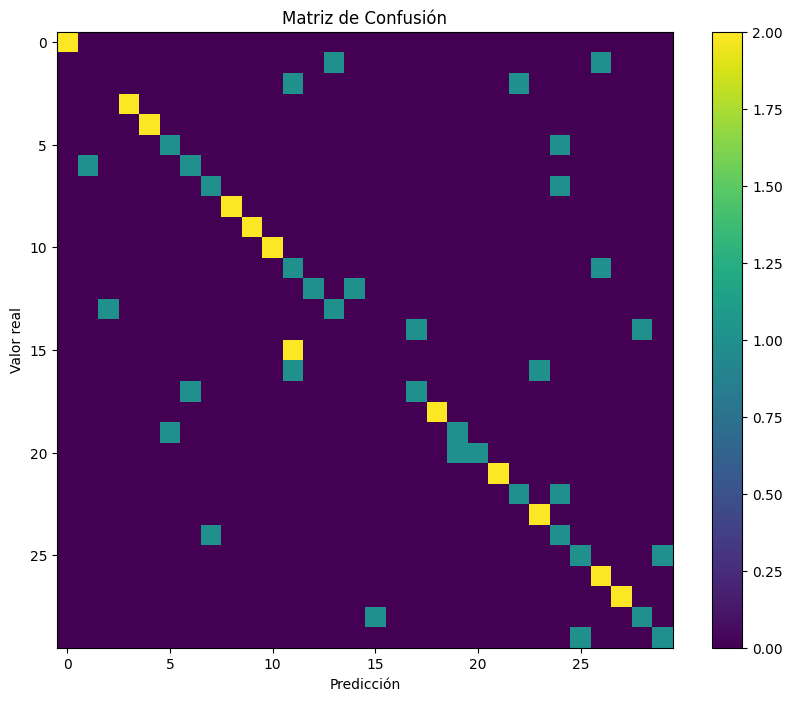

In [ ]:
# ============================================
# 19. MATRIZ DE CONFUSIÓN
# ============================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.title("Matriz de Confusión")

plt.xlabel("Predicción")

plt.ylabel("Valor real")

plt.colorbar()

plt.show()

In [ ]:
# ============================================
# 20. GUARDAR MODELO
# ============================================

MODEL_PATH = "/content/modelo_cnn.keras"

model.save(MODEL_PATH)

print("Modelo guardado:")
print(MODEL_PATH)

Modelo guardado:
/content/modelo_cnn.keras


In [ ]:
# ============================================
# 21. DESCARGAR MODELO
# ============================================

from google.colab import files

files.download(
    "/content/modelo_cnn.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================
# 22. GUARDAR MÉTRICAS
# ============================================

import pandas as pd

resultados = pd.DataFrame({

    "Modelo": ["CNN"],

    "Configuracion": [
        "128x128x3"
    ],

    "Accuracy": [
        accuracy
    ],

    "Precision": [
        precision
    ],

    "Recall": [
        recall
    ],

    "F1-Score": [
        f1
    ]
})

resultados

,Modelo,Configuracion,Accuracy,Precision,Recall,F1-Score
0,CNN,128x128x3,0.6,0.587222,0.6,0.580635


In [ ]:
# ============================================
# 23. DESCARGAR RESULTADOS
# ============================================

resultados.to_csv(
    "/content/resultados_cnn.csv",
    index=False
)

files.download(
    "/content/resultados_cnn.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install fastapi uvicorn python-multipart nest-asyncio pyngrok

In [ ]:
import os

MODEL_PATH = "/content/modelo_cnn.keras"

if os.path.exists(MODEL_PATH):
    print("Modelo encontrado correctamente")
    print(MODEL_PATH)
else:
    print("No se encontró el modelo")

Modelo encontrado correctamente
/content/modelo_cnn.keras


In [ ]:
import tensorflow as tf

model_api = tf.keras.models.load_model(
    "/content/modelo_cnn.keras"
)

print("Modelo CNN cargado correctamente")

model_api.summary()

Modelo CNN cargado correctamente


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,925,532 (37.86 MB)

 Trainable params: 3,308,510 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,617,022 (25.24 MB)

In [ ]:
NUM_CLASSES = model_api.output_shape[-1]

CLASES = [
    f"clase_{i+1:02d}"
    for i in range(NUM_CLASSES)
]

print("Cantidad de clases:", NUM_CLASSES)
print(CLASES)

Cantidad de clases: 30
['clase_01', 'clase_02', 'clase_03', 'clase_04', 'clase_05', 'clase_06', 'clase_07', 'clase_08', 'clase_09', 'clase_10', 'clase_11', 'clase_12', 'clase_13', 'clase_14', 'clase_15', 'clase_16', 'clase_17', 'clase_18', 'clase_19', 'clase_20', 'clase_21', 'clase_22', 'clase_23', 'clase_24', 'clase_25', 'clase_26', 'clase_27', 'clase_28', 'clase_29', 'clase_30']


In [ ]:
import numpy as np
from PIL import Image
import io

def preparar_imagen(contenido):

    imagen = Image.open(
        io.BytesIO(contenido)
    ).convert("RGB")

    imagen = imagen.resize(
        (128, 128)
    )

    imagen = np.array(
        imagen,
        dtype=np.float32
    )

    # Normalización
    imagen = imagen / 255.0

    # (128,128,3) -> (1,128,128,3)
    imagen = np.expand_dims(
        imagen,
        axis=0
    )

    return imagen

In [ ]:
from fastapi import FastAPI, UploadFile, File
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI(
    title="API CNN - Evaluación Parcial 2",
    version="1.0"
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

print("FastAPI creada correctamente")

FastAPI creada correctamente


In [ ]:
@app.get("/")
def inicio():

    return {
        "estado": "API funcionando",
        "modelo": "CNN",
        "entrada": "128x128x3"
    }

In [ ]:
@app.post("/predecir")
async def predecir(
    archivo: UploadFile = File(...)
):

    try:

        contenido = await archivo.read()

        imagen = preparar_imagen(
            contenido
        )

        predicciones = model_api.predict(
            imagen,
            verbose=0
        )

        indice = int(
            np.argmax(predicciones[0])
        )

        confianza = float(
            np.max(predicciones[0])
        )

        clase = CLASES[indice]

        return {
            "resultado": clase,
            "confianza": round(confianza, 4),
            "entrada": "128x128x3"
        }

    except Exception as error:

        return {
            "error": str(error)
        }

In [ ]:
UMBRAL = 0.60

In [ ]:
@app.post("/predecir")
async def predecir(
    archivo: UploadFile = File(...)
):

    try:

        contenido = await archivo.read()

        imagen = preparar_imagen(
            contenido
        )

        predicciones = model_api.predict(
            imagen,
            verbose=0
        )

        indice = int(
            np.argmax(predicciones[0])
        )

        confianza = float(
            np.max(predicciones[0])
        )

        if confianza < UMBRAL:

            resultado = "No reconocido"

        else:

            resultado = CLASES[indice]

        return {
            "resultado": resultado,
            "confianza": round(confianza, 4),
            "entrada": "128x128x3"
        }

    except Exception as error:

        return {
            "error": str(error)
        }

In [ ]:
import nest_asyncio
import uvicorn
import threading

nest_asyncio.apply()

def iniciar_api():

    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000
    )

thread = threading.Thread(
    target=iniciar_api
)

thread.daemon = True
thread.start()

print("Servidor iniciado en el puerto 8000")

Servidor iniciado en el puerto 8000


In [ ]:
import requests
import time

time.sleep(2)

respuesta = requests.get(
    "http://127.0.0.1:8000/"
)

print(respuesta.status_code)
print(respuesta.json())

INFO:     127.0.0.1:55836 - "GET / HTTP/1.1" 200 OK
200
{'estado': 'API funcionando', 'modelo': 'CNN', 'entrada': '128x128x3'}


In [ ]:
from google.colab import files

imagen_prueba = files.upload()

RUTA_PRUEBA = list(
    imagen_prueba.keys()
)[0]

print("Imagen seleccionada:")
print(RUTA_PRUEBA)

Saving IMG_4159.jpeg to IMG_4159.jpeg
Imagen seleccionada:
IMG_4159.jpeg


In [ ]:
import requests

with open(RUTA_PRUEBA, "rb") as imagen:

    respuesta = requests.post(
        "http://127.0.0.1:8000/predecir",
        files={
            "archivo": imagen
        }
    )

print("Código:", respuesta.status_code)
print("Respuesta:")
print(respuesta.json())

INFO:     127.0.0.1:52924 - "POST /predecir HTTP/1.1" 200 OK
Código: 200
Respuesta:
{'resultado': 'clase_15', 'confianza': 1.0, 'entrada': '128x128x3'}


In [ ]:
!pip install pyngrok

In [ ]:
from pyngrok import ngrok

In [ ]:
NGROK_TOKEN = "3IrmeTYEAHu0hnCyq9YA8kqR6sT_6weGdV4AyVBtzU3WKExTe"

ngrok.set_auth_token(NGROK_TOKEN)

print("Token configurado correctamente")

Token configurado correctamente


In [ ]:
from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(8000)

print("====================================")
print("URL PÚBLICA DE LA API")
print("====================================")
print(public_url)

URL PÚBLICA DE LA API
NgrokTunnel: "https://suspend-idealism-vaseline.ngrok-free.dev" -> "http://localhost:8000"


In [ ]:
API_URL = public_url.public_url

print("API pública:")
print(API_URL)

print("\nEndpoint:")
print(API_URL + "/predecir")

print("\nDocumentación:")
print(API_URL + "/docs")

API pública:
https://suspend-idealism-vaseline.ngrok-free.dev

Endpoint:
https://suspend-idealism-vaseline.ngrok-free.dev/predecir

Documentación:
https://suspend-idealism-vaseline.ngrok-free.dev/docs


In [ ]:
import requests

respuesta = requests.get(
    API_URL + "/"
)

print("Código:", respuesta.status_code)
print(respuesta.json())

INFO:     136.66.105.38:0 - "GET / HTTP/1.1" 200 OK
Código: 200
{'estado': 'API funcionando', 'modelo': 'CNN', 'entrada': '128x128x3'}


In [ ]:
print(API_URL + "/docs")

https://suspend-idealism-vaseline.ngrok-free.dev/docs


In [ ]:
from google.colab import files

uploaded_test = files.upload()

imagen_test = list(uploaded_test.keys())[0]

Saving 02fc6aa3-1cab-4205-ad98-ed6abaa9fe68 4.JPG to 02fc6aa3-1cab-4205-ad98-ed6abaa9fe68 4.JPG


In [ ]:
import requests

with open(imagen_test, "rb") as imagen:

    respuesta = requests.post(
        API_URL + "/predecir",
        files={
            "archivo": (
                imagen_test,
                imagen,
                "image/jpeg"
            )
        }
    )

print("Código HTTP:")
print(respuesta.status_code)

print("\nRespuesta de la API:")
print(respuesta.json())

INFO:     136.66.105.38:0 - "POST /predecir HTTP/1.1" 200 OK
Código HTTP:
200

Respuesta de la API:
{'resultado': 'clase_15', 'confianza': 0.9973, 'entrada': '128x128x3'}


In [ ]:
import os
import uuid
from datetime import datetime
from fastapi import UploadFile, File

CARPETA_RECIBIDOS = "/content/imagenes_recibidas"
os.makedirs(CARPETA_RECIBIDOS, exist_ok=True)

@app.post("/predecir")
async def predecir(archivo: UploadFile = File(...)):

    try:
        contenido = await archivo.read()

        # Crear nombre único
        nombre = f"{datetime.now().strftime('%H%M%S')}_{uuid.uuid4().hex[:6]}.jpg"
        ruta = os.path.join(CARPETA_RECIBIDOS, nombre)

        # Guardar temporalmente
        with open(ruta, "wb") as f:
            f.write(contenido)

        print("\n==============================")
        print("NUEVA IMAGEN RECIBIDA")
        print("==============================")
        print("Archivo:", archivo.filename)
        print("Guardada en:", ruta)
        print("Bytes:", len(contenido))

        imagen = preparar_imagen(contenido)

        predicciones = model_api.predict(
            imagen,
            verbose=0
        )

        indice = int(np.argmax(predicciones[0]))
        confianza = float(np.max(predicciones[0]))

        if confianza < UMBRAL:
            resultado = "No reconocido"
        else:
            resultado = CLASES[indice]

        print("Resultado:", resultado)
        print("Confianza:", round(confianza, 4))
        print("==============================")

        return {
            "resultado": resultado,
            "confianza": round(confianza, 4),
            "entrada": "128x128x3"
        }

    except Exception as error:
        print("ERROR:", error)

        return {
            "error": str(error)
        }

In [ ]:
import os

archivos = os.listdir("/content/imagenes_recibidas")

print("Total recibidas:", len(archivos))

for archivo in archivos:
    print(archivo)

Total recibidas: 0


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

CARPETA = "/content/imagenes_recibidas"

archivos = os.listdir(CARPETA)

for archivo in archivos[-5:]:

    ruta = os.path.join(CARPETA, archivo)

    imagen = Image.open(ruta)

    plt.figure(figsize=(4, 4))
    plt.imshow(imagen)
    plt.title(archivo)
    plt.axis("off")
    plt.show()

In [ ]:
# ============================================
# 50. ANALIZAR CONFIANZA DEL MODELO
# ============================================

def analizar_prediccion(imagen):

    pred = model_api.predict(
        imagen,
        verbose=0
    )[0]

    orden = np.argsort(pred)[::-1]

    print("TOP 5 PREDICCIONES")
    print("==============================")

    for indice in orden[:5]:

        print(
            CLASES[indice],
            "->",
            f"{pred[indice] * 100:.2f}%"
        )

    return pred

In [ ]:
# ============================================
# 51. REVISAR GENERALIZACIÓN
# ============================================

train_acc = history.history["accuracy"][-1]
val_acc = history.history["val_accuracy"][-1]

train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

print("RESULTADOS FINALES")
print("==============================")

print(
    f"Accuracy entrenamiento: {train_acc*100:.2f}%"
)

print(
    f"Accuracy validación: {val_acc*100:.2f}%"
)

print(
    f"Loss entrenamiento: {train_loss:.4f}"
)

print(
    f"Loss validación: {val_loss:.4f}"
)

print("==============================")

diferencia = train_acc - val_acc

if diferencia > 0.20:

    print(
        "Posible sobreajuste:"
        " existe una diferencia grande entre"
        " entrenamiento y validación."
    )

else:

    print(
        "No se observa una diferencia"
        " extremadamente grande."
    )

RESULTADOS FINALES
Accuracy entrenamiento: 98.75%
Accuracy validación: 60.00%
Loss entrenamiento: 0.0337
Loss validación: 3.1336
Posible sobreajuste: existe una diferencia grande entre entrenamiento y validación.


In [ ]:
# ============================================
# 52. MÉTRICAS POR CLASE
# ============================================

from sklearn.metrics import classification_report

reporte = classification_report(
    y_test,
    y_pred,
    target_names=CLASES,
    zero_division=0
)

print(reporte)

              precision    recall  f1-score   support

    clase_01       1.00      1.00      1.00         2
    clase_02       0.00      0.00      0.00         2
    clase_03       0.00      0.00      0.00         2
    clase_04       1.00      1.00      1.00         2
    clase_05       1.00      1.00      1.00         2
    clase_06       0.50      0.50      0.50         2
    clase_07       0.50      0.50      0.50         2
    clase_08       0.50      0.50      0.50         2
    clase_09       1.00      1.00      1.00         2
    clase_10       1.00      1.00      1.00         2
    clase_11       1.00      1.00      1.00         2
    clase_12       0.20      0.50      0.29         2
    clase_13       1.00      0.50      0.67         2
    clase_14       0.50      0.50      0.50         2
    clase_15       0.00      0.00      0.00         2
    clase_16       0.00      0.00      0.00         2
    clase_17       0.00      0.00      0.00         2
    clase_18       0.50    

In [ ]:
# Usamos la variable existente 'y_probability' en lugar de 'predicciones'
indice = np.argmax(y_probability[0])

In [ ]:
# ============================================
# 53. REGLAS DE RECHAZO
# ============================================

UMBRAL_CONFIANZA = 0.70
MARGEN_MINIMO = 0.20

In [ ]:
def decidir_resultado(predicciones):

    probabilidades = predicciones[0]

    orden = np.argsort(
        probabilidades
    )[::-1]

    primero = orden[0]
    segundo = orden[1]

    confianza_1 = float(
        probabilidades[primero]
    )

    confianza_2 = float(
        probabilidades[segundo]
    )

    margen = confianza_1 - confianza_2

    if (
        confianza_1 < UMBRAL_CONFIANZA
        or margen < MARGEN_MINIMO
    ):

        return {
            "resultado": "No reconocido",
            "confianza": confianza_1,
            "margen": margen
        }

    return {
        "resultado": CLASES[primero],
        "confianza": confianza_1,
        "margen": margen
    }

In [ ]:
from google.colab import files

uploaded = files.upload()

RUTA_NUEVA = list(uploaded.keys())[0]

Saving a2ab6157-df79-4033-a744-daa665c1fa00 4.JPG to a2ab6157-df79-4033-a744-daa665c1fa00 4.JPG


In [ ]:
with open(RUTA_NUEVA, "rb") as archivo:

    contenido = archivo.read()

imagen_nueva = preparar_imagen(
    contenido
)

predicciones = model_api.predict(
    imagen_nueva,
    verbose=0
)

resultado = decidir_resultado(
    predicciones
)

print("==============================")
print("RESULTADO")
print("==============================")

print(
    "Resultado:",
    resultado["resultado"]
)

print(
    "Confianza:",
    f'{resultado["confianza"]*100:.2f}%'
)

print(
    "Margen:",
    f'{resultado["margen"]*100:.2f}%'
)

RESULTADO
Resultado: No reconocido
Confianza: 44.30%
Margen: 1.98%


In [ ]:
analizar_prediccion(
    imagen_nueva
)

TOP 5 PREDICCIONES
clase_30 -> 44.30%
clase_29 -> 42.32%
clase_12 -> 6.94%
clase_18 -> 3.41%
clase_15 -> 0.77%


array([3.0840046e-04, 1.2301971e-03, 1.3256373e-03, 3.7716674e-03,
       3.4227309e-05, 5.3030293e-05, 9.6666068e-04, 9.4465431e-05,
       1.9410510e-03, 8.8835586e-06, 3.9825652e-04, 6.9426745e-02,
       4.4472772e-03, 4.3749078e-06, 7.6727602e-03, 7.7542396e-08,
       7.0446078e-03, 3.4090459e-02, 6.1400642e-05, 1.6473870e-04,
       3.9949111e-04, 1.0670976e-04, 3.2551528e-05, 2.6653993e-07,
       1.4152893e-04, 5.3071930e-05, 2.3906705e-07, 1.0455787e-05,
       4.2322829e-01, 4.4298249e-01], dtype=float32)

In [ ]:
@app.post("/predecir")
async def predecir(
    archivo: UploadFile = File(...)
):

    try:

        contenido = await archivo.read()

        imagen = preparar_imagen(
            contenido
        )

        predicciones = model_api.predict(
            imagen,
            verbose=0
        )

        decision = decidir_resultado(
            predicciones
        )

        print("\n==============================")
        print("NUEVA SOLICITUD")
        print("==============================")

        print(
            "Resultado:",
            decision["resultado"]
        )

        print(
            "Confianza:",
            round(
                decision["confianza"],
                4
            )
        )

        print(
            "Margen:",
            round(
                decision["margen"],
                4
            )
        )

        return {

            "resultado":
                decision["resultado"],

            "confianza":
                round(
                    decision["confianza"],
                    4
                ),

            "entrada":
                "128x128x3"
        }

    except Exception as error:

        print("ERROR:", error)

        return {
            "error": str(error)
        }

In [ ]:
# ============================================
# 57. DIAGNÓSTICO GENERAL
# ============================================

train_loss, train_acc = model_api.evaluate(
    X_train,
    y_train,
    verbose=0
)

test_loss, test_acc = model_api.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("====================================")
print("DIAGNÓSTICO DEL MODELO")
print("====================================")

print(f"Accuracy entrenamiento : {train_acc*100:.2f}%")
print(f"Accuracy prueba         : {test_acc*100:.2f}%")

print(f"Loss entrenamiento      : {train_loss:.4f}")
print(f"Loss prueba             : {test_loss:.4f}")

print("------------------------------------")

diferencia = train_acc - test_acc

if diferencia > 0.20:
    print("⚠ POSIBLE SOBREAJUSTE")
    print("El modelo funciona mucho mejor con")
    print("los datos que ya conoce.")
elif test_acc < 0.50:
    print("⚠ RENDIMIENTO BAJO")
    print("El modelo todavía tiene dificultades")
    print("para separar correctamente las clases.")
else:
    print("✓ Generalización razonable")

DIAGNÓSTICO DEL MODELO
Accuracy entrenamiento : 100.00%
Accuracy prueba         : 60.00%
Loss entrenamiento      : 0.0005
Loss prueba             : 3.1336
------------------------------------
⚠ POSIBLE SOBREAJUSTE
El modelo funciona mucho mejor con
los datos que ya conoce.


In [ ]:
# ============================================
# 58. CANTIDAD DE IMÁGENES POR CLASE
# ============================================

import numpy as np

valores, cantidades = np.unique(
    y,
    return_counts=True
)

print("IMÁGENES POR CLASE")
print("============================")

for clase, cantidad in zip(
    valores,
    cantidades
):
    print(
        f"{CLASES[clase]}: {cantidad}"
    )

print("============================")
print("Total:", len(y))

IMÁGENES POR CLASE
clase_01: 10
clase_02: 10
clase_03: 10
clase_04: 10
clase_05: 10
clase_06: 10
clase_07: 10
clase_08: 10
clase_09: 10
clase_10: 10
clase_11: 10
clase_12: 10
clase_13: 10
clase_14: 10
clase_15: 10
clase_16: 10
clase_17: 10
clase_18: 10
clase_19: 10
clase_20: 10
clase_21: 10
clase_22: 10
clase_23: 10
clase_24: 10
clase_25: 10
clase_26: 10
clase_27: 10
clase_28: 10
clase_29: 10
clase_30: 10
Total: 300


PRUEBA CONTROLADA
Clase esperada: clase_23
Clase obtenida: clase_25
Confianza: 97.43%


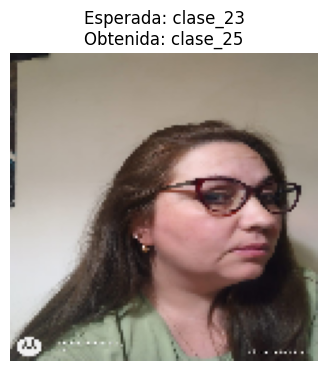

In [ ]:
# ============================================
# 59. PRUEBA CONTROLADA
# ============================================

indice_prueba = 0

imagen = X_test[indice_prueba]

real = int(
    y_test[indice_prueba]
)

entrada = np.expand_dims(
    imagen,
    axis=0
)

pred = model_api.predict(
    entrada,
    verbose=0
)[0]

predicha = int(
    np.argmax(pred)
)

confianza = float(
    np.max(pred)
)

print("================================")
print("PRUEBA CONTROLADA")
print("================================")

print(
    "Clase esperada:",
    CLASES[real]
)

print(
    "Clase obtenida:",
    CLASES[predicha]
)

print(
    "Confianza:",
    f"{confianza*100:.2f}%"
)

plt.figure(figsize=(4,4))
plt.imshow(imagen)
plt.title(
    f"Esperada: {CLASES[real]}\n"
    f"Obtenida: {CLASES[predicha]}"
)
plt.axis("off")
plt.show()

In [ ]:
# ============================================
# 60. PROBAR 10 EJEMPLOS
# ============================================

cantidad = min(10, len(X_test))

for i in range(cantidad):

    entrada = np.expand_dims(
        X_test[i],
        axis=0
    )

    pred = model_api.predict(
        entrada,
        verbose=0
    )[0]

    predicha = np.argmax(pred)
    real = y_test[i]

    confianza = np.max(pred)

    estado = (
        "OK"
        if predicha == real
        else "ERROR"
    )

    print(
        f"{i:02d} | "
        f"Real: {CLASES[real]} | "
        f"Pred: {CLASES[predicha]} | "
        f"{confianza*100:.1f}% | "
        f"{estado}"
    )

00 | Real: clase_23 | Pred: clase_25 | 97.4% | ERROR
01 | Real: clase_13 | Pred: clase_13 | 100.0% | OK
02 | Real: clase_03 | Pred: clase_12 | 30.8% | ERROR
03 | Real: clase_15 | Pred: clase_18 | 75.6% | ERROR
04 | Real: clase_25 | Pred: clase_25 | 100.0% | OK
05 | Real: clase_18 | Pred: clase_18 | 77.5% | OK
06 | Real: clase_16 | Pred: clase_12 | 66.0% | ERROR
07 | Real: clase_08 | Pred: clase_25 | 97.9% | ERROR
08 | Real: clase_27 | Pred: clase_27 | 100.0% | OK
09 | Real: clase_22 | Pred: clase_22 | 77.9% | OK


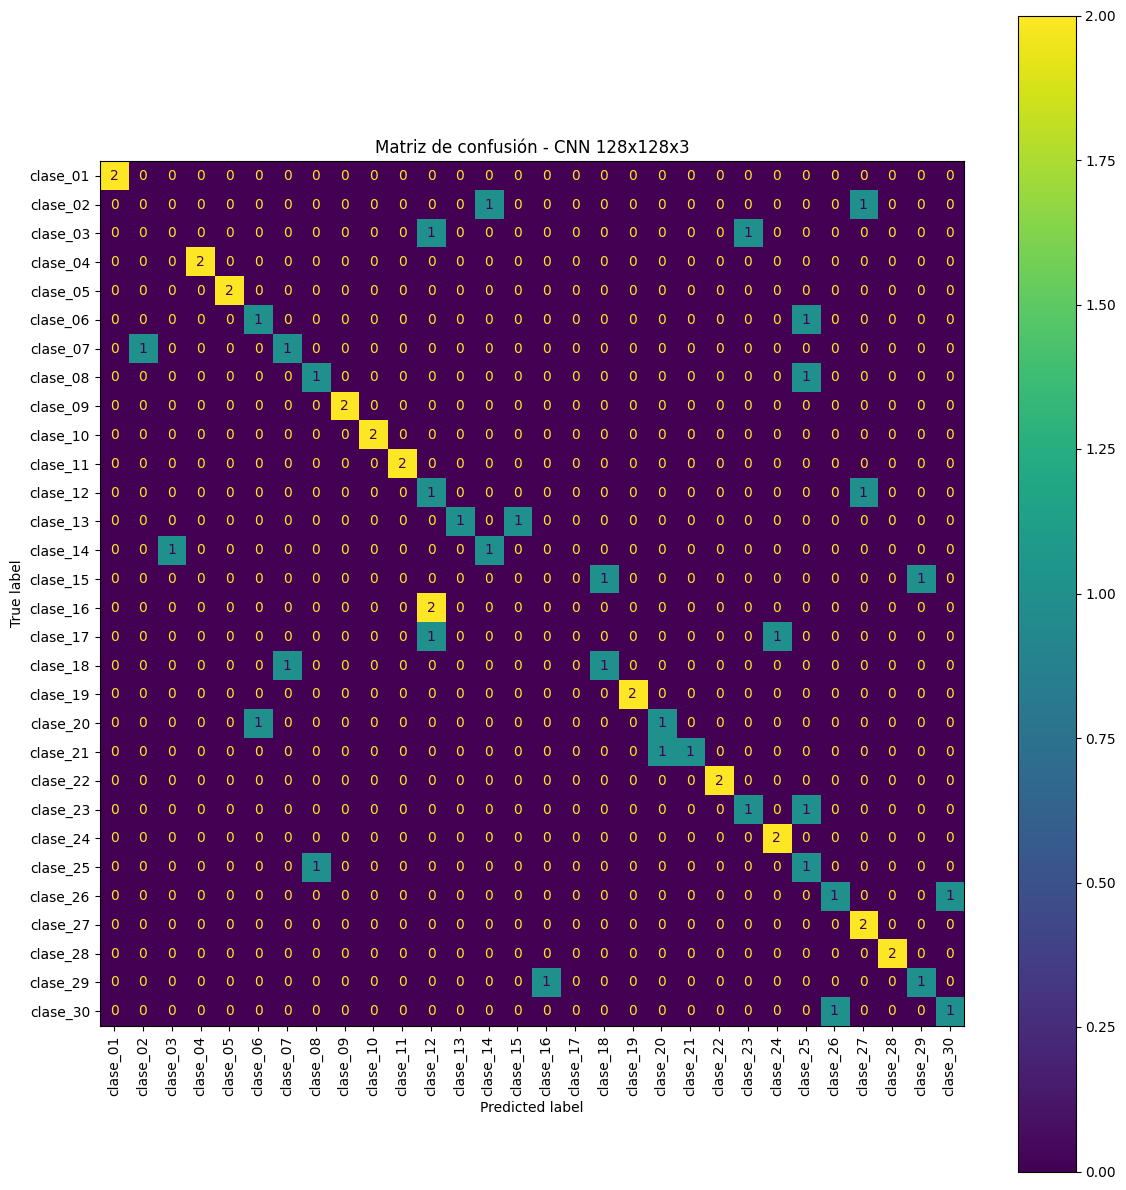

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predicciones_test = model_api.predict(
    X_test,
    verbose=0
)

y_pred_test = np.argmax(
    predicciones_test,
    axis=1
)

fig, ax = plt.subplots(
    figsize=(12, 12)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=CLASES,
    xticks_rotation=90,
    ax=ax
)

plt.title(
    "Matriz de confusión - CNN 128x128x3"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# 62. BLOQUE RESIDUAL
# ============================================

import tensorflow as tf
from tensorflow.keras import layers, Model

def bloque_residual(x, filtros, reducir=False):

    stride = 2 if reducir else 1
    shortcut = x

    # Camino principal
    x = layers.Conv2D(
        filtros,
        3,
        strides=stride,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filtros,
        3,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)

    # Ajustar shortcut cuando cambian dimensiones
    if reducir or shortcut.shape[-1] != filtros:

        shortcut = layers.Conv2D(
            filtros,
            1,
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    # Conexión residual
    x = layers.Add()([
        x,
        shortcut
    ])

    x = layers.ReLU()(x)

    return x

In [ ]:
# ============================================
# 63. MODELO RESIDUAL
# ============================================

NUM_CLASSES = len(CLASES)

entrada = layers.Input(
    shape=(128, 128, 3)
)

# Capa inicial
x = layers.Conv2D(
    32,
    7,
    strides=2,
    padding="same",
    use_bias=False
)(entrada)

x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.MaxPooling2D(
    pool_size=3,
    strides=2,
    padding="same"
)(x)

# BLOQUE 1
x = bloque_residual(
    x,
    32
)

x = bloque_residual(
    x,
    32
)

# BLOQUE 2
x = bloque_residual(
    x,
    64,
    reducir=True
)

x = bloque_residual(
    x,
    64
)

# BLOQUE 3
x = bloque_residual(
    x,
    128,
    reducir=True
)

x = bloque_residual(
    x,
    128
)

# Clasificación
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(
    0.4
)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(
    0.3
)(x)

salida = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

modelo_residual = Model(
    entrada,
    salida,
    name="CNN_Residual"
)

modelo_residual.summary()

Model: "CNN_Residual"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      4,704 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │      9,216 │ max_pooling2d_3[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │      9,216 │ re_lu_1[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │      9,216 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │      9,216 │ re_lu_3[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_7[0][0]  

 Total params: 721,790 (2.75 MB)

 Trainable params: 719,550 (2.74 MB)

 Non-trainable params: 2,240 (8.75 KB)

In [ ]:
# ============================================
# 64. COMPILAR
# ============================================

modelo_residual.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print("Modelo residual compilado.")

Modelo residual compilado.


In [ ]:
# ============================================
# 65. CALLBACKS
# ============================================

early_stop = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=8,

    restore_best_weights=True,

    verbose=1
)


reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=4,

    min_lr=0.000001,

    verbose=1
)


checkpoint = tf.keras.callbacks.ModelCheckpoint(

    "/content/mejor_modelo_residual.keras",

    monitor="val_accuracy",

    save_best_only=True,

    verbose=1
)

In [ ]:
# ============================================
# 66. ENTRENAMIENTO
# ============================================

history_residual = modelo_residual.fit(

    X_train,
    y_train,

    validation_data=(
        X_test,
        y_test
    ),

    epochs=60,

    batch_size=16,

    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.0513 - loss: 3.8333
Epoch 1: val_accuracy improved from None to 0.03333, saving model to /content/mejor_modelo_residual.keras

Epoch 1: finished saving model to /content/mejor_modelo_residual.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 38s 611ms/step - accuracy: 0.0625 - loss: 3.8463 - val_accuracy: 0.0333 - val_loss: 3.4038 - learning_rate: 5.0000e-04
Epoch 2/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 615ms/step - accuracy: 0.0815 - loss: 3.3365
Epoch 2: val_accuracy did not improve from 0.03333
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 665ms/step - accuracy: 0.0958 - loss: 3.2357 - val_accuracy: 0.0333 - val_loss: 3.3929 - learning_rate: 5.0000e-04
Epoch 3/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 634ms/step - accuracy: 0.2794 - loss: 2.7329
Epoch 3: val_accuracy improved from 0.03333 to 0.06667, saving model to /content/mejor_modelo_residual.keras

Epoch 3: finished saving model to /content/mejor_modelo_residual.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 702ms/ste

In [ ]:
# ============================================
# 67. CARGAR MEJOR MODELO
# ============================================

mejor_residual = tf.keras.models.load_model(
    "/content/mejor_modelo_residual.keras"
)

print(
    "Mejor modelo residual cargado."
)

Mejor modelo residual cargado.


In [ ]:
# ============================================
# 68. EVALUACIÓN
# ============================================

loss_residual, acc_residual = mejor_residual.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("==============================")
print("MODELO RESIDUAL")
print("==============================")

print(
    f"Accuracy: {acc_residual*100:.2f}%"
)

print(
    f"Loss: {loss_residual:.4f}"
)

MODELO RESIDUAL
Accuracy: 6.67%
Loss: 3.3987


In [ ]:
# ============================================
# 69. PREDICCIONES
# ============================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

prob_residual = mejor_residual.predict(
    X_test,
    verbose=0
)

pred_residual = np.argmax(
    prob_residual,
    axis=1
)

precision_residual = precision_score(
    y_test,
    pred_residual,
    average="weighted",
    zero_division=0
)

recall_residual = recall_score(
    y_test,
    pred_residual,
    average="weighted",
    zero_division=0
)

f1_residual = f1_score(
    y_test,
    pred_residual,
    average="weighted",
    zero_division=0
)

print("==============================")
print("MÉTRICAS")
print("==============================")

print(
    f"Accuracy : {acc_residual*100:.2f}%"
)

print(
    f"Precision: {precision_residual*100:.2f}%"
)

print(
    f"Recall   : {recall_residual*100:.2f}%"
)

print(
    f"F1-Score : {f1_residual*100:.2f}%"
)

MÉTRICAS
Accuracy : 6.67%
Precision: 0.44%
Recall   : 6.67%
F1-Score : 0.83%


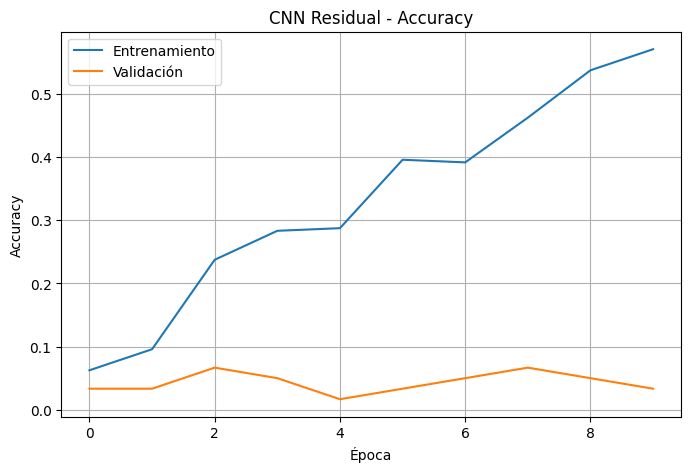

In [ ]:
# ============================================
# 70. GRÁFICO ACCURACY
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history_residual.history["accuracy"],
    label="Entrenamiento"
)

plt.plot(
    history_residual.history["val_accuracy"],
    label="Validación"
)

plt.xlabel("Época")
plt.ylabel("Accuracy")

plt.title(
    "CNN Residual - Accuracy"
)

plt.legend()
plt.grid()

plt.show()

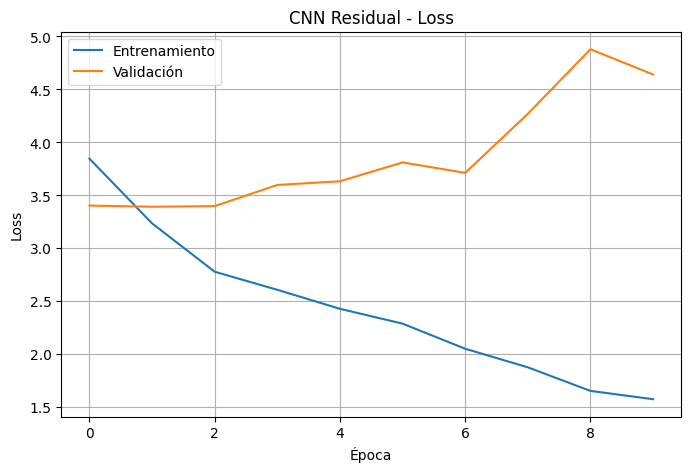

In [ ]:
# ============================================
# 71. GRÁFICO LOSS
# ============================================

plt.figure(figsize=(8,5))

plt.plot(
    history_residual.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    history_residual.history["val_loss"],
    label="Validación"
)

plt.xlabel("Época")
plt.ylabel("Loss")

plt.title(
    "CNN Residual - Loss"
)

plt.legend()
plt.grid()

plt.show()

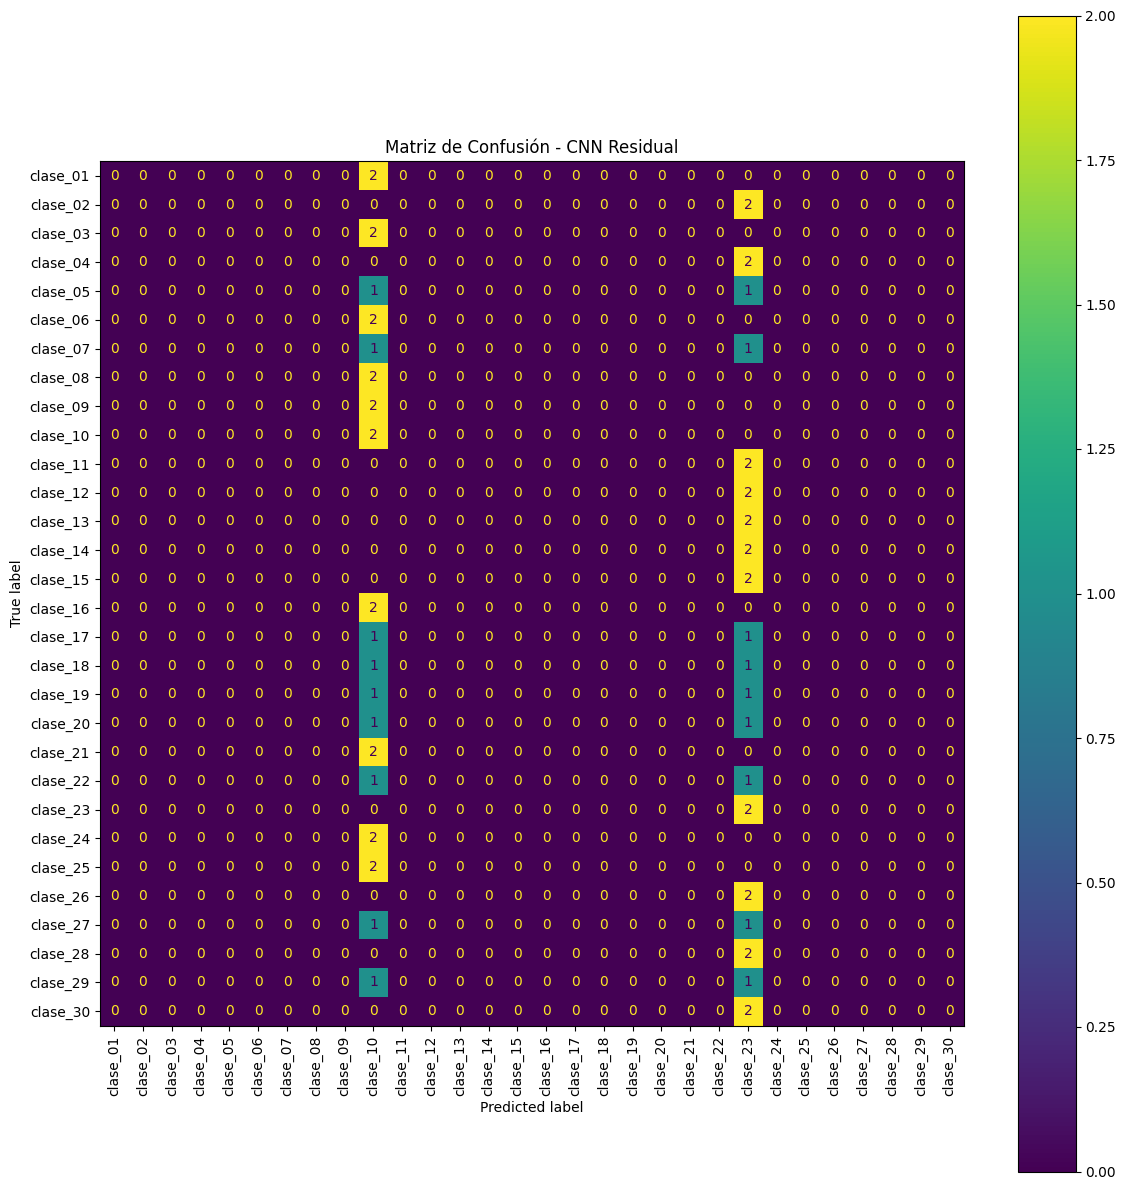

In [ ]:
# ============================================
# 72. MATRIZ DE CONFUSIÓN
# ============================================

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(
    figsize=(12, 12)
)

ConfusionMatrixDisplay.from_predictions(

    y_test,

    pred_residual,

    display_labels=CLASES,

    xticks_rotation=90,

    ax=ax
)

plt.title(
    "Matriz de Confusión - CNN Residual"
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================
# 73. COMPARACIÓN
# ============================================

import pandas as pd

comparacion = pd.DataFrame({

    "Modelo": [
        "CNN",
        "CNN Residual"
    ],

    "Accuracy": [
        accuracy,
        acc_residual
    ],

    "Precision": [
        precision,
        precision_residual
    ],

    "Recall": [
        recall,
        recall_residual
    ],

    "F1-Score": [
        f1,
        f1_residual
    ]
})

comparacion

,Modelo,Accuracy,Precision,Recall,F1-Score
0,CNN,0.600000,0.587222,0.600000,0.580635
1,CNN Residual,0.066667,0.004449,0.066667,0.008341


In [ ]:
# ============================================
# 74. SELECCIONAR MEJOR MODELO
# ============================================

if acc_residual > accuracy:

    print(
        "GANADOR: CNN RESIDUAL"
    )

    modelo_final = mejor_residual

else:

    print(
        "GANADOR: CNN ORIGINAL"
    )

    modelo_final = model

GANADOR: CNN ORIGINAL


In [ ]:
# ============================================
# 75. GUARDAR MODELO FINAL
# ============================================

modelo_final.save(
    "/content/modelo_final.keras"
)

print(
    "Modelo final guardado."
)

Modelo final guardado.


In [ ]:
model_api = tf.keras.models.load_model(
    "/content/modelo_final.keras"
)

print(
    "API usando modelo final."
)

API usando modelo final.
